# Sử dụng model pretrained

Model pretrained là model người khác đã huấn luyện sẵn trên dữ liệu lớn và công bố trọng số, ví dụ ResNet huấn luyện trên ImageNet. Muốn dùng được cần hai thứ: trọng số, và đúng cách xử lý đầu vào lúc model được huấn luyện (kích thước ảnh, cách chuẩn hóa màu). Xử lý sai thì code vẫn chạy nhưng kết quả sai. Bài này nạp một model, chạy dự đoán trên một batch ảnh và kiểm kết quả, trước khi nghĩ tới huấn luyện thêm.

> **Mục tiêu**
>
> - Phân biệt kiến trúc, trọng số, bộ xử lý đầu vào và tập nhãn của một model.
> - Nạp model từ máy, chạy dự đoán theo batch và kiểm kết quả.
> - Ước lượng bộ nhớ cho trọng số.
> - Chuẩn bị file model để chạy khi không có Internet.

## Mô hình có sẵn gồm những gì?

Lập trình thi đấu có kiểu lời giải “đánh bảng”: chương trình chỉ tra một bảng đã tính sẵn ở nhà, còn phần khó nằm trong bảng. Thiếu bảng, code vẫn biên dịch nhưng không trả lời đúng được câu nào. Với mạng neural, kiến trúc là phần code, mô tả các phép toán; trọng số là cái bảng, tức kết quả đã học. `nn.Linear(2, 3)` vừa tạo ra ba phép cộng có trọng số từ hai đầu vào, nhưng những trọng số ngẫu nhiên ấy chưa biết phân loại gì.

Model pretrained là mô hình có trọng số đã được học từ một nhiệm vụ trước đó. Nhiệm vụ trước có thể là phân loại ảnh, dự đoán token bị che hoặc ghép ảnh với mô tả. Nó không nhất thiết trùng với nhiệm vụ của ta. Không có pretrained thì trọng số bắt đầu ngẫu nhiên như bài 3.3; có thì bắt đầu từ chỗ đã học.

Vì sao trọng số học cho nhiệm vụ khác lại có ích? Để phân biệt hơn một triệu ảnh thuộc 1000 lớp của ImageNet, mạng buộc phải học những đặc trưng mà ảnh nào cũng có: cạnh, kết cấu, hình dạng, bộ phận của vật thể. Các tầng sâu dần ghép đặc trưng đơn giản thành đặc trưng phức tạp, và phần lớn chúng không gắn với một lớp cụ thể nào. ImageNet không có lớp “thi đấu” hay “bài giảng”, nhưng ảnh câu lạc bộ vẫn có cạnh, kết cấu, bàn ghế, màn hình, máy chiếu. Chỉ tầng cuối, gọi là head, gắn chặt với 1000 lớp cũ.



Một gói có thể dùng lại cần nhiều thứ đi cùng nhau:

- **Trọng số**: kết quả đã học.
- **Cấu hình**: số lớp và kích thước các tầng.
- **Processor**: cách xử lý đầu vào như resize, thứ tự kênh màu, chuẩn hóa, hoặc tokenizer với chữ.
- **Bảng nhãn**: chỉ số 0, 1, 2… nghĩa là gì.
- **Revision**: đúng phiên bản đã tải.

Nếu dùng trọng số của phiên bản này với tokenizer của phiên bản khác, chương trình có thể vẫn chạy nhưng đầu vào đã đổi ý nghĩa.

Với ảnh, đầu vào thường có shape `(B, C, H, W)`: $B$ là số ảnh trong batch, $C$ là số kênh, $H$ và $W$ là chiều cao và rộng. Với chữ, tokenizer thường tạo `input_ids` và `attention_mask` có shape `(B, L)`, trong đó $L$ là độ dài đã padding. Cùng là `float32` không có nghĩa cùng thang đo.

Processor của các model ảnh huấn luyện trên ImageNet thường chia pixel cho 255, rồi chuẩn hóa từng kênh bằng mean $(0.485, 0.456, 0.406)$ và std $(0.229, 0.224, 0.225)$ của tập ấy. Có processor nhận pixel từ 0 đến 255 và tự chia, có processor nhận ảnh đã chia sẵn. Làm một bước hai lần, hoặc bỏ sót một lần, đều đổi dữ liệu mà không gây lỗi nào.

Trong torchvision, `transforms.ToTensor()` đổi ảnh PIL $(H, W, 3)$ giá trị 0–255 thành tensor float $(3, H, W)$ trong $[0, 1]$; `Normalize` làm việc trên tensor nên đứng sau nó, như `Compose([Resize(...), ToTensor(), Normalize(mean, std)])`.



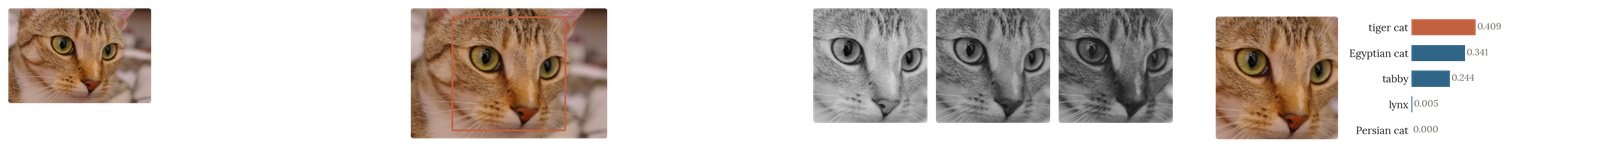

**Hỏi nhanh.** Có kiến trúc ResNet, và trọng số được khởi tạo ngẫu nhiên. Mô hình này đã là một model pretrained chưa?

- A. Rồi, vì tên kiến trúc trùng với model đã công bố
- B. Rồi, sau khi gọi `model.eval()` để suy luận
- C. Chưa, vì chưa nạp trọng số đã học
- D. Chưa, vì phải fine-tune trên dữ liệu mới trước

<details><summary>Đáp án</summary>

C. Chưa, vì chưa nạp trọng số đã học

“Pretrained” nằm ở trọng số, không nằm ở tên kiến trúc. `eval()` chỉ đổi cách Dropout và BatchNorm hoạt động, không thêm được điều gì đã học. Fine-tune là bước tùy chọn về sau: một checkpoint đã học thì dùng được ngay để suy luận hay để trích đặc trưng.

</details>

**Hỏi nhanh.** Processor của checkpoint nhận pixel từ 0 đến 255, tự chia cho 255, rồi trừ mean và chia std. Code của đội lại đã chia cho 255 trước khi gọi processor. Chuyện gì xảy ra?

- A. Báo lỗi kiểu dữ liệu, vì input không còn là số nguyên
- B. Chạy bình thường, nhưng ảnh nào cũng gần như một màu
- C. Kết quả y hệt, vì chia hai lần vẫn giữ thứ tự các pixel
- D. Chỉ chậm hơn một chút, còn dự đoán không đổi

<details><summary>Đáp án</summary>

B. Chạy bình thường, nhưng ảnh nào cũng gần như một màu

Sau hai lần chia, mọi pixel nằm trong $[0, 1/255]$. Sau khi chuẩn hóa, kênh R của mọi ảnh chỉ còn nằm trong khoảng $-2.118$ đến $-2.101$, gần như một hằng số. Shape và kiểu dữ liệu vẫn đúng nên không có lỗi nào, nhưng mạng thấy các ảnh gần như giống nhau, nên dự đoán cũng gần như giống nhau cho mọi ảnh. Thứ tự pixel giữ nguyên cũng không cứu được, vì mạng học trên thang đo cũ chứ không phải trên thứ tự.

</details>

## Thử cơ chế bằng một gói nhỏ chạy offline

Trước khi đụng tới một checkpoint cỡ hàng chục đến hàng trăm MiB, ta đi hết đường dữ liệu trên một gói đủ nhỏ để tính tay. Mỗi mẫu có hai đặc trưng thay cho một ảnh, mạng là `nn.Linear(2, 3)` với trọng số đặt sẵn, đầu ra là ba nhãn hoạt động. Gói này đóng vai checkpoint mà một nhóm khác đã công bố.

Các bước lưu, nạp, tiền xử lý và suy luận giống hệt với model thật, chỉ khác kích thước; vì mọi số đều tính tay được, sai ở bước nào sẽ lộ ngay ở bước ấy.

`state_dict` là ánh xạ từ tên tham số hoặc buffer đến tensor. Ta lưu thêm các số của processor và bảng nhãn trong cùng gói. `BytesIO` đóng vai một tệp trong bộ nhớ; với tệp thật, chỉ cần thay bằng đường dẫn `.pt`.

In [ ]:
import io
import numpy as np
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(0)
source = nn.Linear(2, 3)
with torch.no_grad():
    source.weight.copy_(torch.tensor([[1., -1.], [-1., 1.], [.5, .5]]))
    source.bias.copy_(torch.tensor([0., 0., .25]))

package = {
    "state_dict": source.state_dict(),
    "mean": torch.tensor([10., 10.]),
    "scale": torch.tensor([2., 2.]),
    "labels": ["hoat_dong_A", "hoat_dong_B", "chua_ro"],
}
buffer = io.BytesIO()
torch.save(package, buffer)
buffer.seek(0)
loaded = torch.load(buffer, map_location="cpu", weights_only=True)

model = nn.Linear(2, 3)
model.load_state_dict(loaded["state_dict"], strict=True)
model.eval()
print("shape W:", tuple(model.weight.shape))
print("nhan:", loaded["labels"])

shape W: (3, 2)
nhan: ['hoat_dong_A', 'hoat_dong_B', 'chua_ro']


Ba tham số khi nạp:

- `strict=True` phát hiện tên hoặc shape tham số không khớp, thay vì âm thầm bỏ một tầng.
- `map_location="cpu"` mở tensor đã được lưu ở thiết bị khác lên CPU.
- `weights_only=True`, mặc định từ PyTorch 2.6, chỉ mở tensor và kiểu dữ liệu đơn giản như số, chuỗi, list, dict; nó không chạy code tùy ý có thể nằm trong file pickle. Vì vậy gói nên chứa `state_dict` cùng các số và chuỗi, không chứa cả đối tượng model.

Nạp được cũng chưa có nghĩa là đúng tệp: nguồn và hash vẫn phải kiểm, như ở mục cuối bài.

**Hỏi nhanh.** Checkpoint được lưu từ một model bọc trong `DataParallel`, nên các khóa là `module.weight` và `module.bias`, trong khi model mới chờ `weight` và `bias`. Đội gọi `load_state_dict(sd, strict=False)`. Kết quả là gì?

- A. PyTorch tự bỏ tiền tố `module.` rồi nạp đủ
- B. Báo lỗi ngay khi nạp, vì tên khóa không khớp
- C. Nạp được `bias`, còn `weight` vẫn ngẫu nhiên
- D. Không lỗi gì, nhưng model vẫn giữ trọng số khởi tạo

<details><summary>Đáp án</summary>

D. Không lỗi gì, nhưng model vẫn giữ trọng số khởi tạo

`strict=False` bỏ qua mọi khóa thiếu và thừa. Hàm chỉ trả về `missing_keys=['weight', 'bias']` và `unexpected_keys=['module.weight', 'module.bias']`. Không khóa nào khớp, nên model chạy với trọng số khởi tạo và điểm sụt mà không có lỗi nào. Với `strict=True` thì lỗi hiện ra ngay. Cách sửa là đổi tên khóa, bỏ tiền tố đi, rồi nạp với strict. PyTorch không tự đoán tên, và cũng không có khóa nào được nạp một phần.

</details>

Ta viết processor thành hàm riêng. Với $\mathbf{x}=(12,8)$, trừ $(10,10)$ rồi chia $(2,2)$ cho $\mathbf{z}=(1,-1)$. Mạng tính

$$\boldsymbol{\ell} = W\mathbf{z}+\mathbf{b}=(2,-2,0.25).$$

$\boldsymbol{\ell}$ là vector logits, chưa phải xác suất. Softmax không đổi thứ tự các logits, nên argmax trước hay sau softmax như nhau; softmax chỉ cần khi muốn xác suất, chẳng hạn để nộp xác suất hoặc đặt ngưỡng. Logit lớn nhất nằm ở chỉ số 0, và bảng nhãn đổi chỉ số ấy thành tên.



In [ ]:
def process(raw):
    raw_tensor = torch.as_tensor(raw, dtype=torch.float32)
    return (raw_tensor - loaded["mean"]) / loaded["scale"]

raw = np.array([[12., 8.], [8., 12.], [10., 10.], [14., 6.], [9., 11.]])
with torch.inference_mode():
    logits = model(process(raw))
    predicted = logits.argmax(dim=1)
print(logits.numpy().round(2))
print([loaded["labels"][i] for i in predicted.tolist()])

[[ 2.   -2.    0.25]
 [-2.    2.    0.25]
 [ 0.    0.    0.25]
 [ 4.   -4.    0.25]
 [-1.    1.    0.25]]
['hoat_dong_A', 'hoat_dong_B', 'chua_ro', 'hoat_dong_A', 'hoat_dong_B']


Hàng đầu đúng bằng $(2,-2,0.25)$ như tính tay. Hàng thứ ba có hai đặc trưng bằng trung bình nên thành $(0,0)$ sau processor; chỉ còn bias, và lớp `chua_ro` thắng. Với checkpoint thật không ai tính tay được toàn bộ logits, nhưng cách kiểm vẫn như vậy: shape phải là (số mẫu, số lớp), vài mẫu đã biết đáp án phải ra đúng, và một đường tính độc lập phải khớp (mục sau).

**Hỏi nhanh.** `logits` có shape `(5, 3)`. Muốn mỗi mẫu có một nhãn, ta dùng gì?

- A. `logits.argmax(dim=1)`
- B. `logits.argmax(dim=0)`
- C. `logits.argmax()`
- D. `logits.max(dim=1).values`

<details><summary>Đáp án</summary>

A. `logits.argmax(dim=1)`

Chiều 1 chạy qua ba lớp của cùng một mẫu, nên argmax theo chiều ấy cho năm chỉ số, mỗi mẫu một. `dim=0` so năm mẫu trong cùng một lớp, ra ba số. `argmax()` không có `dim` thì làm phẳng tensor 15 phần tử rồi trả về một số duy nhất. `.values` là giá trị logit lớn nhất, không phải chỉ số của lớp.

</details>

## Batch phải giữ nguyên ý nghĩa và thứ tự

Một batch là nhiều mẫu được tính chung để tận dụng phép toán ma trận. Nó không phải một mẫu mới được tạo bằng cách trộn các ảnh. Batch size đổi lượng công việc mỗi lần gọi, còn thứ tự đầu ra phải khớp với thứ tự đầu vào.



Ở chế độ suy luận, mạng tuyến tính này cho cùng đáp án với mọi cách chia batch. Ta kiểm với cả kết quả chạy một lần và một bản NumPy độc lập; kiểm thứ hai giúp bắt lỗi chuyển vị ma trận, không chỉ lỗi ghép batch.

In [ ]:
def infer_batches(raw, batch_size):
    rows = []
    with torch.inference_mode():
        for start in range(0, len(raw), batch_size):
            rows.append(model(process(raw[start:start + batch_size])))
    return torch.cat(rows, dim=0)

batched = infer_batches(raw, batch_size=2)
z_numpy = (raw - np.array([10., 10.])) / np.array([2., 2.])
W_numpy = np.array([[1., -1.], [-1., 1.], [.5, .5]])
expected = z_numpy @ W_numpy.T + np.array([0., 0., .25])
print("batch khop:", torch.allclose(batched, logits))
print("NumPy khop:", np.allclose(batched.numpy(), expected))
print("so mau:", len(batched))

batch khop: True
NumPy khop: True
so mau: 5


Ba dòng cần lần lượt xác nhận cách chia batch, phép toán và số mẫu. Với dữ liệu thật, còn phải giữ `id` cùng mỗi hàng. Nếu DataLoader shuffle rồi ghi kết quả theo thứ tự CSV ban đầu, mọi tensor đều đúng shape mà file nộp vẫn sai.

`model.eval()` và `torch.inference_mode()` giải quyết hai việc:

- `eval()` đặt các tầng như Dropout và BatchNorm vào chế độ đánh giá; nó không tắt autograd.
- `inference_mode()` bỏ theo dõi gradient để suy luận gọn hơn, giống `no_grad()` nhưng chặt hơn; nó không tự gọi `eval()`.

Tensor tạo trong `inference_mode()` không dùng được cho phép tính cần backward; nếu sau đó muốn học một head trên embedding (bài 4.2), lưu embedding thành mảng NumPy hoặc `.clone()` ra tensor thường trước.

Mạng ảnh pretrained thường có BatchNorm, và đó là thêm một lý do để gọi `eval()`. Ở chế độ train, BatchNorm chuẩn hóa mỗi mẫu bằng mean và variance của chính batch chứa nó, nên đầu ra của một ảnh phụ thuộc những ảnh đi cùng. Ở chế độ eval, nó dùng running statistics đã lưu trong checkpoint, và mọi cách chia batch lại cho cùng kết quả như mạng tuyến tính ở trên.

**Hỏi nhanh.** CNN pretrained có BatchNorm. Đội quên gọi `eval()`, nhưng có `inference_mode()`. Chạy cùng tập test với batch 32 rồi với batch 8, hai file nộp khác nhau ở vài dòng. Vì sao?

- A. `inference_mode()` làm phép tính không còn tất định
- B. Ở chế độ train, BatchNorm dùng thống kê của từng batch
- C. Batch cuối thiếu mẫu nên các dòng bị lệch hàng
- D. Batch nhỏ làm trọng số được cập nhật nhiều lần hơn

<details><summary>Đáp án</summary>

B. Ở chế độ train, BatchNorm dùng thống kê của từng batch

Ở chế độ train, cùng một ảnh được chuẩn hóa bằng thống kê của batch chứa nó, nên đổi batch là đổi logits. Cùng hai ảnh, chạy riêng thành batch 2 hay nằm trong batch 5, cho logits khác nhau ở chế độ train, và trùng nhau ở chế độ eval. Tệ hơn, running statistics trong model còn bị cập nhật theo thống kê của test, kể cả trong `inference_mode()`. Batch cuối thiếu mẫu thì làm sai số dòng, chứ không làm vài nhãn đổi. `inference_mode()` không thêm yếu tố ngẫu nhiên. Không có optimizer thì trọng số không được cập nhật.

</details>

**Hỏi nhanh.** Model đã gọi `eval()`, nhưng vòng dự đoán không bọc trong `inference_mode()` hay `no_grad()`. Tham số vẫn có `requires_grad=True`, còn input thì không. Câu nào đúng?

- A. Không ghi graph, vì `eval()` đã tắt autograd
- B. Không ghi graph, vì input không cần gradient
- C. Vẫn ghi graph, nhưng chỉ khi chạy trên GPU
- D. Vẫn ghi graph, vì `eval()` không đụng tới autograd

<details><summary>Đáp án</summary>

D. Vẫn ghi graph, vì `eval()` không đụng tới autograd

Graph được ghi khi có một đầu vào của phép tính cần gradient, và tham số của model đã đủ điều kiện ấy, dù input không cần. `eval()` chỉ đổi cách Dropout và BatchNorm chạy, còn thiết bị thì không liên quan. Logits vẫn đúng, nhưng mỗi kết quả kéo theo graph của nó, nên gom logits qua nhiều batch sẽ hết bộ nhớ dần.

</details>

## Ước lượng bộ nhớ trước khi chạy

Nếu mô hình có $P$ tham số, mỗi tham số chiếm $s$ byte, bộ nhớ thô của trọng số là $Ps$. `float32` dùng 4 byte, `float16` dùng 2 byte. MiB là $2^{20}$ byte; đừng lẫn với MB là $10^6$ byte. Một mô hình 100 triệu tham số có phần trọng số `float32` khoảng 381.47 MiB, hoặc `float16` khoảng 190.73 MiB.

Kích thước ảnh cũng đổi ra số được. Ảnh $1920 \times 1080$ có 1920 điểm ảnh theo chiều ngang, 1080 theo chiều dọc. Ảnh RGB $32 \times 32$ có $32 \cdot 32 \cdot 3 = 3072$ số; ảnh $100 \times 100$ lưu 1 byte mỗi kênh là 30 000 byte. Số điểm ảnh tăng theo bình phương cạnh: thu $4000 \times 3000$ về $400 \times 300$ bớt 100 lần số pixel, giảm $640 \times 640$ về $320 \times 320$ bớt khoảng 4 lần khối tính của mạng tích chập.

In [ ]:
P = 100_000_000
print("FP32 MiB:", round(P * 4 / 2**20, 2))
print("FP16 MiB:", round(P * 2 / 2**20, 2))
input_bytes = 16 * 3 * 224 * 224 * 4
print("input batch MiB:", round(input_bytes / 2**20, 2))
actual_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
print("mang tuyen tinh bytes:", actual_bytes)

FP32 MiB: 381.47
FP16 MiB: 190.73
input batch MiB: 9.19
mang tuyen tinh bytes: 36


Mạng nhỏ có $3\cdot2+3=9$ tham số, mỗi số 4 byte, nên 36 byte. Input batch 16 ảnh RGB cỡ $224\times224$ là một phần khác: $16\cdot3\cdot224\cdot224\cdot4$ byte, khoảng 9.19 MiB. Khi chạy còn có activation trung gian, buffer, vùng làm việc của thư viện và bộ nhớ dự trữ.

Input và phần lớn activation của mạng tích chập tăng tỉ lệ với $B\cdot H\cdot W$, nên gấp đôi cạnh ảnh tốn ngang gấp bốn batch. Khi training còn có gradient và trạng thái optimizer. Vì vậy “trọng số vừa bộ nhớ” chưa đủ để kết luận “batch này chạy được”. Cách chắc chắn là đo một batch nhỏ trên đúng thiết bị rồi tăng dần.



**Hỏi nhanh.** Một batch 16 ảnh RGB $224\times 224$ kiểu `float32` chiếm 9.19 MiB. Đổi sang batch 32 và ảnh $448\times 448$ thì tensor input chiếm bao nhiêu?

- A. 18.38 MiB
- B. 36.75 MiB
- C. 73.50 MiB
- D. 147.00 MiB

<details><summary>Đáp án</summary>

C. 73.50 MiB

Batch gấp 2. Số pixel mỗi ảnh gấp $2^2 = 4$, vì cả chiều cao lẫn chiều rộng đều gấp đôi. Vậy tổng gấp 8: $32\cdot 3\cdot 448\cdot 448\cdot 4/2^{20} = 73.5$ MiB. Ra 18.38 là chỉ tính batch. Ra 36.75 là coi cạnh gấp đôi thì số pixel gấp đôi. Ra 147 là nhân thêm 2, như thể số kênh cũng đổi. Phần lớn activation cũng tăng theo cùng tỉ lệ, nên gấp đôi cạnh ảnh tốn hơn hẳn gấp đôi batch.

</details>

## Dùng model pretrained thật

Với bộ tìm kiếm của câu lạc bộ, việc đầu tiên là đọc model card: model học trên dữ liệu gì, nhận input nào, xuất ra nhãn nào, license cho phép dùng ra sao. Model chỉ học tiếng Anh sẽ yếu với chú thích tiếng Việt. Head phân loại ImageNet chỉ chọn trong 1000 lớp cũ, không tự biến thành head “sinh hoạt”, “thi đấu”, “bài giảng” của câu lạc bộ. Phần dùng lại được là các tầng bên dưới: bài 4.2 lấy đặc trưng từ đó, bài 4.3 học head mới.

**Hỏi nhanh.** Đội đưa ảnh câu lạc bộ vào một ResNet học trên ImageNet, còn nguyên head, rồi lấy argmax trên 1000 logits. Kết quả là gì?

- A. Nhãn của câu lạc bộ, nếu ảnh đủ rõ và đúng cỡ
- B. Một lớp của ImageNet, không phải nhãn câu lạc bộ
- C. Báo lỗi shape, vì 1000 lớp không khớp ba nhãn mới
- D. Một nhãn ngẫu nhiên, vì model chưa thấy ảnh này

<details><summary>Đáp án</summary>

B. Một lớp của ImageNet, không phải nhãn câu lạc bộ

Head cuối có đúng 1000 đầu ra, mỗi đầu ra gắn với một lớp ImageNet, nên argmax luôn là một chỉ số từ 0 đến 999. Không có lỗi shape, vì model không biết đội muốn bao nhiêu nhãn. Kết quả cũng không ngẫu nhiên: model gọi tên lớp ImageNet gần nhất với những gì nó thấy. Muốn nhãn mới thì lấy đặc trưng ở trước head (bài 4.2), hoặc thay head rồi học (bài 4.3).

</details>

[Script của chương](recipes/README.md) làm việc này theo hai lượt:

1. **Lượt có mạng** (`download_assets.py --download`) tải đúng một revision, tức một commit 40 ký tự hex chứ không phải nhánh `main` có thể đổi, rồi ghi model ID, license đã đọc, kích thước và SHA-256 của từng tệp vào `ASSET.json`.
2. **Lượt offline** kiểm lại mọi hash, đặt `HF_HUB_OFFLINE=1`, nạp model cùng tokenizer hoặc processor từ đường dẫn local với `local_files_only=True`, chạy dữ liệu nhỏ của mình và ghi môi trường cùng kết quả vào `RESULT.json`.

Đọc kết quả theo thứ tự: hash khớp thì tệp đúng; shape và ID khớp thì đường dữ liệu đúng; chỉ khi đó điểm validation mới nói về chất lượng của model trên bài.

**Hỏi nhanh.** Hai tuần sau, đội tải lại cùng model ID từ nhánh `main`, chạy năm ảnh kiểm ở chế độ eval, và thấy logits khác lần trước ngay từ chữ số đầu. Nên kiểm gì đầu tiên?

- A. Commit và SHA-256, so với `ASSET.json` cũ
- B. Seed của NumPy và PyTorch trong notebook
- C. Batch size, vì đổi batch là đổi logits
- D. Phiên bản CUDA, vì GPU khác cho số khác

<details><summary>Đáp án</summary>

A. Commit và SHA-256, so với `ASSET.json` cũ

Nhánh `main` có thể đã được cập nhật trọng số hoặc processor. So commit và hash thì biết các byte có còn như cũ không. Suy luận ở chế độ eval không có yếu tố ngẫu nhiên, nên seed không phải nghi phạm đầu tiên. Đã eval thì batch size không làm đổi logits. GPU khác chỉ làm lệch ở những chữ số rất nhỏ, không phải chữ số đầu.

</details>

## Khi đi thi

- Đọc quy định về model, Internet và thư viện trước khi chuẩn bị.
- Đầu giờ, nạp model từ đường dẫn local, chạy một batch và tạo một file nộp thử.
- Resize, mean/std hay tokenizer phải giống hệt giữa validation và test; lưu chúng cạnh trọng số.

## Tóm tắt

- Model pretrained gồm trọng số đã học, kiến trúc, processor và bảng nhãn; thiếu hay lệch một phần thì code vẫn chạy nhưng kết quả sai.
- Suy luận: gọi `eval()`, tắt gradient, giữ `id` qua batch rồi đối chiếu shape và vài kết quả đã biết.
- Bộ nhớ trọng số là $Ps$ byte; tổng bộ nhớ khi chạy phải đo.
- Model thật cần đúng revision, license, processor, hash và thử chạy offline; chất lượng trên bài mới chỉ biết được qua validation.

## Kiểm tra cuối bài

**Câu 1.** Câu lạc bộ có 300 ảnh gán nhãn “sinh hoạt”, “thi đấu”, “bài giảng”, và ImageNet không có lớp nào như vậy. Vì sao backbone học trên ImageNet vẫn thường tốt hơn khởi tạo ngẫu nhiên?

- A. Dữ liệu lớn và đa dạng dạy mạng những đặc trưng ảnh dùng chung được
- B. ImageNet đã chứa sẵn ảnh hoạt động của câu lạc bộ
- C. Model pretrained luôn cho kết quả tốt nhất ở mọi bài
- D. Head 1000 lớp tự đổi được sang ba nhãn mới

<details><summary>Đáp án</summary>

A. Dữ liệu lớn và đa dạng dạy mạng những đặc trưng ảnh dùng chung được

Để phân biệt hơn một triệu ảnh của 1000 lớp, mạng phải học cạnh, kết cấu, hình dạng, các bộ phận của vật thể. Đó là những đặc trưng có ích cho hầu hết ảnh, kể cả ảnh câu lạc bộ. Với 300 ảnh, học những đặc trưng ấy từ đầu rất dễ overfit. ImageNet không có lớp “thi đấu”. “Luôn tốt nhất” là sai: ảnh y khoa hay ảnh vệ tinh có thể khác xa ImageNet, và lợi ích vẫn phải đo bằng validation. Head cũ chỉ biết 1000 lớp cũ, nên phải thay hoặc học một head mới.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 213](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=77)

</details>

**Câu 2.** ResNet-50 nhận input `(B, 3, 224, 224)`. Phần đầu, gồm conv stride 2 rồi max-pool stride 2, đưa ảnh về $56\times 56$. `layer1` giữ $56\times 56$ và cho ra 256 kênh. Khối đầu của `layer2` có conv $3\times 3$ stride 2 trên 128 kênh, rồi conv $1\times 1$ mở ra 512 kênh. Đầu ra của `layer2` có shape gì?

- A. `(B, 128, 28, 28)`
- B. `(B, 512, 28, 28)`
- C. `(B, 512, 56, 56)`
- D. `(B, 28, 28, 512)`

<details><summary>Đáp án</summary>

B. `(B, 512, 28, 28)`

Stride 2 chia đôi cạnh, nên $56 \to 28$. Số kênh ra là của conv cuối khối, tức 512; 128 chỉ là chiều hẹp bên trong khối bottleneck. Quên stride thì ra $56\times 56$. Đặt kênh ở cuối là quy ước channels-last, không phải của PyTorch. Kiểm bằng `torchvision.models.resnet50(weights=None)`, không cần tải trọng số: batch 2 cho đầu ra `layer2` có shape `(2, 512, 28, 28)`. Phải biết shape của từng tầng trước khi cắt backbone hay gắn head mới.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 8.2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=20)

</details>

**Câu 3.** Với `model = resnet50(weights=None)`, biểu thức nào cho đúng số tham số học được?
```py
n1 = len(list(model.parameters()))
n2 = sum(t.numel() for t in model.state_dict().values())
n3 = sum(p.numel() for p in model.parameters())
n4 = sum(p.numel() * p.element_size() for p in model.parameters())
```

- A. `n1`
- B. `n2`
- C. `n3`
- D. `n4`

<details><summary>Đáp án</summary>

C. `n3`

`n3` cộng số phần tử của mọi tham số, ra 25 557 032. `n1` đếm số tensor tham số, tức 161, chứ không đếm phần tử. `n2` cộng cả buffer của BatchNorm, gồm `running_mean`, `running_var`, `num_batches_tracked`, vốn không được học bằng gradient, nên ra 25 610 205. `n4` là số byte, 102 228 128 với `float32`, gấp 4 lần số tham số. Nếu một phần đã bị đóng băng, thêm điều kiện `if p.requires_grad` để chỉ đếm phần còn học.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 8.1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=20)

</details>

**Câu 4.** Processor ImageNet chia pixel cho 255, rồi với kênh R thì trừ mean 0.485 và chia std 0.229. Một pixel kênh R bằng 128 trở thành bao nhiêu, làm tròn 3 chữ số?

- A. $-2.118$
- B. $0.074$
- C. $0.502$
- D. $556.834$

<details><summary>Đáp án</summary>

B. $0.074$

$128/255 \approx 0.502$, rồi $(0.502 - 0.485)/0.229 \approx 0.074$. Ra $0.502$ là dừng lại sau bước chia 255. Ra $556.834 = (128 - 0.485)/0.229$ là quên chia 255: số lớn gấp hàng nghìn lần thang mà mạng đã học, mạng vẫn chạy và trả về nhãn vô nghĩa. $-2.118$ là giá trị của pixel 0.

</details>

**Câu 5.** Config của checkpoint ghi `id2label = {0: "cat", 1: "dog", 2: "bird"}`. Logits của một ảnh là $(-1, 2, 0.5)$. Đội lại tự tạo danh sách nhãn bằng `sorted(set(train_labels))`, tức `["bird", "cat", "dog"]`, để ghi file nộp. Nhãn đúng và nhãn đội ghi lần lượt là gì?

- A. bird và cat
- B. cat và bird
- C. dog và dog
- D. dog và cat

<details><summary>Đáp án</summary>

D. dog và cat

Argmax là chỉ số 1, theo `id2label` của checkpoint là “dog”. Danh sách đã sắp xếp lại đặt “cat” ở chỉ số 1, nên file nộp ghi “cat” mà không có lỗi nào. “dog và dog” chỉ đúng khi đội dùng bảng nhãn của checkpoint. “bird” là lớp có logit 0.5, không phải lớn nhất. Chỉ số đầu ra chỉ có nghĩa thông qua bảng nhãn đi kèm checkpoint: hãy đọc nó từ config, đừng dựng lại.

</details>

**Câu 6.** Đội chuyển model đã eval sang `float16` trên GPU để suy luận nhanh hơn, giữ `input_ids` ở kiểu số nguyên. Nên kỳ vọng gì, và kiểm gì?

- A. Trọng số chỉ còn nửa bộ nhớ, và phải chấm lại validation
- B. Accuracy chắc chắn giảm, không đáng để đổi
- C. Logits giống hệt đến từng bit, không cần chấm lại
- D. Chỉ có lợi trên CPU, còn GPU không nhanh hơn

<details><summary>Đáp án</summary>

A. Trọng số chỉ còn nửa bộ nhớ, và phải chấm lại validation

Mỗi tham số giảm từ 4 byte xuống 2 byte, và GPU có phần cứng FP16 thường chạy nhanh hơn. Đổi lại, logits lệch một chút vì làm tròn. Đa số nhãn không đổi, nhưng mẫu nằm sát ranh giới có thể đổi, nên phải chấm lại validation trước khi nộp. “Chắc chắn giảm” và “giống hệt từng bit” là hai cực, đều sai. Lợi ích về tốc độ của FP16 nằm ở GPU, không phải ở CPU.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 300](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=115)

</details>

**Câu 7.** ResNet-50 có 25 557 032 tham số. Ở `float16`, phần trọng số chiếm khoảng bao nhiêu?

- A. 24.37 MiB
- B. 48.75 MiB
- C. 51.11 MiB
- D. 97.49 MiB

<details><summary>Đáp án</summary>

B. 48.75 MiB

$25\,557\,032\cdot 2/2^{20} \approx 48.75$ MiB. 51.11 là số MB, tức $10^6$ byte, chứ không phải MiB. 97.49 MiB là phần trọng số ở `float32`. 24.37 là coi `float16` chỉ có 1 byte. Đây mới chỉ là trọng số, chưa có input, activation hay vùng làm việc.

</details>

**Câu 8.** Trọng số chiếm 2 GiB trên GPU 4 GiB. Suy luận với batch 1 thì chạy được, batch 128 thì báo out-of-memory. Giải thích nào phù hợp nhất?

- A. Số tham số của weights tự tăng theo batch size
- B. Ở chế độ eval vẫn giữ hai moment của Adam cho mỗi lần forward
- C. Checkpoint 2 GiB thì tổng VRAM luôn đúng bằng 2 GiB
- D. Input và activation tăng theo batch, còn weights thì cố định

<details><summary>Đáp án</summary>

D. Input và activation tăng theo batch, còn weights thì cố định

Weights cố định 2 GiB, dù batch là 1 hay 128. Input, activation và vùng làm việc của thư viện tăng gần tuyến tính theo batch: batch 1 còn dư chỗ, batch 128 thì vượt quá 2 GiB còn lại. Moment của Adam chỉ có khi train. Số tham số không phụ thuộc vào batch. Cách làm là đo đỉnh bộ nhớ với batch tăng dần, rồi chọn batch lớn nhất còn an toàn, hoặc chia nhỏ batch.

</details>

**Câu 9.** Hai hàm suy luận PyTorch, một chạy cả tập, một chia batch, cùng gọi một hàm `process` tự viết, và cho logits bằng nhau. Viết lại công thức từ đầu bằng NumPy thì thêm được gì?

- A. Chứng minh checkpoint đã học đúng mọi lớp
- B. Bảo đảm output trên GPU giống hệt CPU đến từng bit
- C. Bắt được lỗi nằm trong phần mà hai hàm dùng chung
- D. Tăng accuracy, vì có thêm một framework để kiểm

<details><summary>Đáp án</summary>

C. Bắt được lỗi nằm trong phần mà hai hàm dùng chung

Nếu `process` chia cho mean thay vì trừ mean, cả hai hàm PyTorch cùng sai và vẫn khớp nhau. Đường NumPy không dùng chung `process`, nên làm lộ ra lỗi ấy. Nó kiểm phép tính trên dữ liệu nhỏ, không nói gì về chất lượng của checkpoint, không so GPU với CPU, và không làm accuracy tăng.

</details>

**Câu 10.** Trên Colab, đội lưu `torch.save(model, "m.pt")`, tức lưu cả đối tượng model. Máy chấm dùng PyTorch mới, và `torch.load("m.pt")` báo lỗi “Weights only load failed”. Lần sau nên lưu thế nào cho bền?

- A. Lưu `state_dict()` kèm config, rồi dựng model và nạp vào
- B. Gọi `model.save("m.pt")` như trong Keras
- C. Vẫn dùng `torch.save(model)`, và nạp với `weights_only=False`
- D. Chỉ lưu dự đoán trên validation thay cho model

<details><summary>Đáp án</summary>

A. Lưu `state_dict()` kèm config, rồi dựng model và nạp vào

`torch.save(model)` pickle cả đối tượng: nạp lại cần đúng định nghĩa lớp, ở đúng đường import. Từ PyTorch 2.6, `torch.load` mặc định `weights_only=True`, nên từ chối pickle ấy và báo `UnpicklingError`. `state_dict` chỉ gồm tên và tensor, nạp được với `weights_only=True`. Code dựng kiến trúc nằm trong notebook, còn config và bảng nhãn đi kèm. `nn.Module` không có hàm `.save`. Với file tự tạo, `weights_only=False` mở được, nhưng vẫn phụ thuộc định nghĩa lớp và chạy mọi code trong file, nên không dùng với file lạ. Dự đoán trên validation thì không dùng được cho test.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 134](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=51)

</details>

## Đọc thêm

- [PyTorch — serialization notes](https://docs.pytorch.org/docs/stable/notes/serialization.html): đọc `state_dict`, `weights_only` và việc nạp checkpoint.
- [PyTorch — autograd mechanics](https://docs.pytorch.org/docs/stable/notes/autograd.html): phân biệt chế độ đánh giá với chế độ theo dõi gradient.
- [Transformers — offline mode](https://huggingface.co/docs/transformers/installation#offline-mode): chuẩn bị cache, `HF_HUB_OFFLINE` và `local_files_only`.
- [Hugging Face Hub — download guide](https://huggingface.co/docs/huggingface_hub/guides/download): tải theo revision và chọn đúng các tệp asset.
- [Torchvision — ResNet18 weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html): xem processor, metadata và khác biệt giữa kiến trúc với trọng số đã học.

Nguồn ảnh: ảnh hoa là ảnh mẫu `flower.jpg` kèm scikit-learn (vultilion, Flickr, CC BY 2.0); ảnh mèo là ảnh mẫu `chelsea` kèm scikit-image (Stefan van der Walt, CC0).